# Phân tích khám phá dữ liệu (EDA) — Máy lạnh treo tường trên Tiki

## 1. Cấu trúc dữ liệu

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/raw/tiki_may_lanh_229.csv')

In [37]:
# Xem kích thước bộ dữ liệu (số dòng, số cột)
df.shape

(229, 16)

In [38]:
# Tên cột và kiểu dữ liệu
df.dtypes

id                         int64
name                      object
brand_name                object
price                      int64
original_price             int64
discount                   int64
discount_rate              int64
rating_average           float64
review_count               int64
quantity_sold              int64
thumbnail_url             object
primary_category_name     object
primary_category_path     object
url_path                  object
seller_name               object
origin                    object
dtype: object

In [39]:
# Tổng quan bộ dữ liệu, kiểu dữ liệu, số lượng giá trị không rỗng
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 229 entries, 0 to 228
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     229 non-null    int64  
 1   name                   229 non-null    object 
 2   brand_name             229 non-null    object 
 3   price                  229 non-null    int64  
 4   original_price         229 non-null    int64  
 5   discount               229 non-null    int64  
 6   discount_rate          229 non-null    int64  
 7   rating_average         229 non-null    float64
 8   review_count           229 non-null    int64  
 9   quantity_sold          229 non-null    int64  
 10  thumbnail_url          229 non-null    object 
 11  primary_category_name  229 non-null    object 
 12  primary_category_path  229 non-null    object 
 13  url_path               229 non-null    object 
 14  seller_name            229 non-null    object 
 15  origin

In [40]:
# Xem 5 mẫu đầu
df.head()

,id,name,brand_name,price,original_price,discount,discount_rate,rating_average,review_count,quantity_sold,thumbnail_url,primary_category_name,primary_category_path,url_path,seller_name,origin
0,279370905,Máy lạnh LG Inverter 1 HP IOC09S1 - Hàng Chính...,LG,5100000,9081000,3981000,44,4.0,3,266,https://salt.tikicdn.com/cache/280x280/ts/prod...,Máy lạnh treo tường,1/2/4221/3865/67236,may-lanh-lg-inverter-1-hp-ioc09s1-hang-chinh-h...,Tiki Trading,Thái Lan
1,279317558,Máy Lạnh Sharp Inverter 1 HP AH-XP10DSW - Hàng...,Sharp,6911000,10490000,3579000,34,0.0,0,1,https://salt.tikicdn.com/cache/280x280/ts/prod...,Máy lạnh treo tường,1/2/4221/3865/67236,may-lanh-sharp-inverter-1-hp-ah-xp10dsw-hang-c...,Điện Máy Phú Sĩ,Indonesia
2,279232761,Máy lạnh LG Inverter 1HP IFC09M1/ 1.5HP IFC12M...,LG,5444000,8790000,3346000,38,0.0,0,1,https://salt.tikicdn.com/cache/280x280/ts/prod...,Máy lạnh treo tường,1/2/4221/3865/67236,may-lanh-lg-inverter-1hp-ifc09m1-1-5hp-ifc12m1...,Điện Máy Phú Sĩ,Indonesia
3,278589553,Máy lạnh Toshiba Inverter 1.5 HP RAS-H13Z1KCVG...,Toshiba,10018000,13690000,3672000,27,0.0,0,1,https://salt.tikicdn.com/cache/280x280/ts/prod...,Máy lạnh treo tường,1/2/4221/3865/67236,may-lanh-toshiba-inverter-1-5-hp-ras-h13z1kcvg...,Điện Máy Phú Sĩ,Thái Lan
4,216333101,Máy lạnh Panasonic inverter cao cấp 1.5Hp CU/C...,Panasonic,13146000,16300000,3154000,19,0.0,0,0,https://salt.tikicdn.com/cache/280x280/ts/prod...,Máy lạnh treo tường,1/2/4221/3865/67236,may-lanh-panasonic-inverter-cao-cap-1-5hp-cu-c...,Điện Máy Phú Sĩ,Malaysia


### Phân loại biến định lượng và định tính (Slide 8–10, Bài 04)
- **Định lượng liên tục (Continuous):** `price`, `original_price`, `discount`, `discount_rate`, `rating_average`
- **Định lượng rời rạc (Discrete):** `review_count`, `quantity_sold`
- **Định tính (Categorical - không có thứ tự):** `brand_name`, `seller_name`, `origin`, `primary_category_name`, `primary_category_path` *(và các cột định danh/văn bản/đường dẫn: `id`, `name`, `thumbnail_url`, `url_path`)*
- **Định tính có thứ tự (Ordinal):** Không có trong 16 cột gốc.

In [41]:
df.select_dtypes(include=['int64', 'float64']).columns

Index(['id', 'price', 'original_price', 'discount', 'discount_rate',
       'rating_average', 'review_count', 'quantity_sold'],
      dtype='object')

In [42]:
df.select_dtypes(include=['object', 'string']).columns

Index(['name', 'brand_name', 'thumbnail_url', 'primary_category_name',
       'primary_category_path', 'url_path', 'seller_name', 'origin'],
      dtype='object')

## 2. Phân tích khuyết

In [43]:
df.isnull().sum()

id                       0
name                     0
brand_name               0
price                    0
original_price           0
discount                 0
discount_rate            0
rating_average           0
review_count             0
quantity_sold            0
thumbnail_url            0
primary_category_name    0
primary_category_path    0
url_path                 0
seller_name              0
origin                   1
dtype: int64

In [44]:
df[df['origin'].isnull()]

,id,name,brand_name,price,original_price,discount,discount_rate,rating_average,review_count,quantity_sold,thumbnail_url,primary_category_name,primary_category_path,url_path,seller_name,origin
145,279600081,AS-24CR4RBBDBI00 - Máy lạnh Hisense 2.5 HP KH...,Hisense,10050000,15990000,5940000,37,0.0,0,0,https://salt.tikicdn.com/cache/280x280/ts/prod...,Máy lạnh treo tường,1/2/4221/3865/67236,as-24cr4rbbdbi00-may-lanh-hisense-2-5-hp-khong...,ĐIỆN MÁY TẤN TÀI,NaN


## 3. Đơn biến

In [45]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,229.0,2.223860e+08,8.106275e+07,635342.0,172975276.0,274861771.0,279257450.0,279603535.0
price,229.0,1.361166e+07,8.291142e+06,4359000.0,8239000.0,11322000.0,15940000.0,52240000.0
original_price,229.0,1.685288e+07,9.467684e+06,5191000.0,10091900.0,14400000.0,19990000.0,65699000.0
discount,229.0,3.241214e+06,3.854396e+06,50000.0,50000.0,2351000.0,5254000.0,23220000.0
discount_rate,229.0,1.891703e+01,1.750657e+01,0.0,0.0,20.0,37.0,48.0
rating_average,229.0,1.790393e-01,8.975097e-01,0.0,0.0,0.0,0.0,5.0
review_count,229.0,6.550218e-02,3.628437e-01,0.0,0.0,0.0,0.0,3.0
quantity_sold,229.0,1.419214e+00,1.757837e+01,0.0,0.0,0.0,0.0,266.0


In [46]:
df['price_trieu'] = df['price'] / 1_000_000


In [47]:
df['price_trieu'].describe().T

count    229.000000
mean      13.611662
std        8.291142
min        4.359000
25%        8.239000
50%       11.322000
75%       15.940000
max       52.240000
Name: price_trieu, dtype: float64

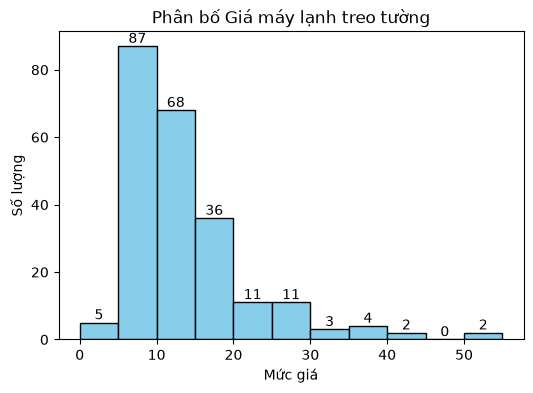

In [60]:
ax = df['price_trieu'].plot(kind='hist', bins=[0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55] ,
              color='skyblue',
              edgecolor='black',
              figsize=(6,4))
plt.title('Phân bố Giá máy lạnh treo tường')
plt.xlabel('Mức giá')
plt.ylabel('Số lượng')
ax.bar_label(ax.containers[0])
plt.show()

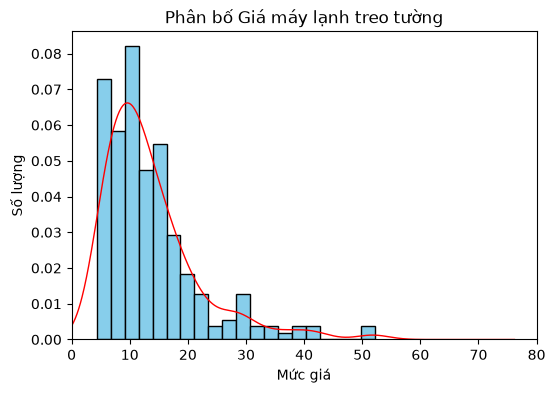

In [50]:
ax = df['price_trieu'].plot(kind='kde', color='red', linewidth=1)
df['price_trieu'].plot(kind='hist', bins=20,
              color='skyblue',
              edgecolor='black',
              figsize=(6,4), ax = ax, density= True, xlim=(0,80))
plt.title('Phân bố Giá máy lạnh treo tường')
plt.xlabel('Mức giá')
plt.ylabel('Số lượng')
plt.show()

In [63]:
df['log_price_trieu'] = np.log(df['price_trieu'])


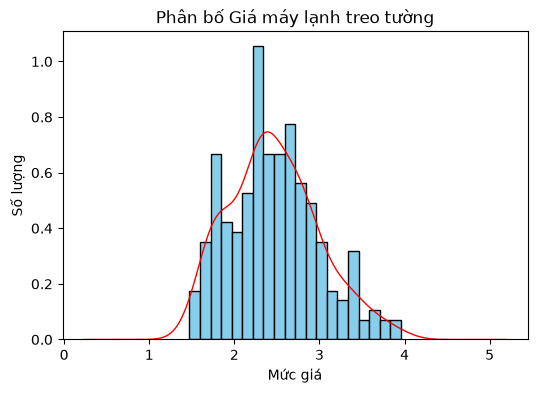

In [66]:
ax = df['log_price_trieu'].plot(kind='kde', color='red', linewidth=1)
df['log_price_trieu'].plot(kind='hist', bins=20,
              color='skyblue',
              edgecolor='black',
              figsize=(6,4), ax = ax, density= True)
plt.title('Phân bố Giá máy lạnh treo tường')
plt.xlabel('Mức giá')
plt.ylabel('Số lượng')
plt.show()

<Axes: >

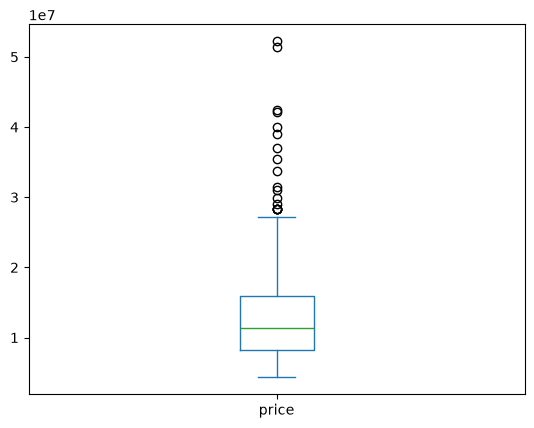

In [67]:
df['price'].plot(kind='box')

<Axes: >

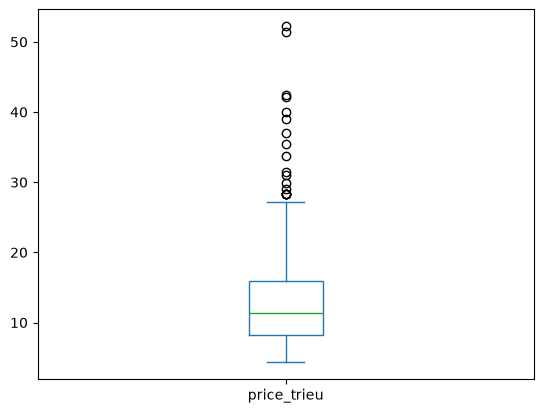

In [68]:
df['price_trieu'].plot(kind='box')

<Axes: >

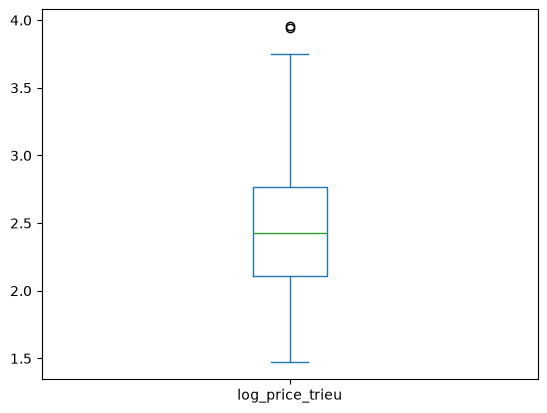

In [69]:
df['log_price_trieu'].plot(kind='box')

In [70]:
s = df['log_price_trieu']
Q1, Q3 = s.quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

outliers = df[(s < lower) | (s > upper)]
print(f'Ngưỡng: [{lower:.3f}, {upper:.3f}]')
print('Số outlier:', len(outliers))
outliers[['name', 'price_trieu', 'log_price_trieu']]


Ngưỡng: [1.119, 3.759]
Số outlier: 2


,name,price_trieu,log_price_trieu
82,Hệ Thống Máy Lạnh Multi Split PANASONIC 4 HP -...,51.35,3.938665
210,Hệ Thống Máy Lạnh Multi S Daikin Inverter Comb...,52.24,3.955848


## 4. Tương quan

In [72]:
import re
import numpy as np

def extract_hp(name):
    vals = re.findall(r'(\d+(?:[.,]\d+)?)\s*HP', str(name), flags=re.IGNORECASE)
    vals = {float(v.replace(',', '.')) for v in vals}
    return vals.pop() if len(vals) == 1 else np.nan   # 0 hoặc nhiều mức HP -> NaN

df['hp'] = df['name'].apply(extract_hp)

print(df['hp'].value_counts(dropna=False).sort_index())


hp
1.0    71
1.5    60
2.0    40
2.5    25
3.0     3
NaN    30
Name: count, dtype: int64


## 5. Hai biến và nhiều biến

## 6. Kiểm định

## 7. Ngoại lệ